# Problema 2 — Regressão logística para doença cardíaca

## Preparação dos dados

O objetivo é estimar a presença de doença cardíaca registrada no conjunto Cleveland.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

In [2]:
colunas = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
df = pd.read_csv('data/heart_disease/processed.cleveland.data',
                 names=colunas, na_values='?')
print('Registros originais:', len(df))

Registros originais: 303


In [3]:
print('Ausentes por coluna:')
display(df.isna().sum()[lambda s: s > 0])
print('Registros incompletos:', df.isna().any(axis=1).sum())

Ausentes por coluna:


ca      4
thal    2
dtype: int64

Registros incompletos: 6


In [4]:
df = df.dropna()
print('Registros após limpeza:', len(df))

Registros após limpeza: 297


In [5]:
df['target'] = (df['target'] > 0).astype(int)
print('Classes: 0 = sem doença; 1 = com doença')
display(df['target'].value_counts().sort_index().to_frame('amostras'))

Classes: 0 = sem doença; 1 = com doença


,amostras
target,
0,160
1,137


In [6]:
X, y = df.drop(columns='target'), df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Treino:', len(X_train), '| teste:', len(X_test))
display(pd.DataFrame({'treino': y_train.value_counts().sort_index(),
                      'teste': y_test.value_counts().sort_index()}))

Treino: 237 | teste: 60


,treino,teste
target,,
0,128,32
1,109,28


In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Tarefa 1 — Treinamento da regressão logística

Usamos `LogisticRegression` com os parâmetros exigidos:

| Parâmetro | Valor |
|---|---|
| `solver` | `liblinear` |
| `random_state` | 42 |
| `max_iter` | 1.000 |

Após o ajuste, consultamos `n_iter_` para verificar quantas iterações foram realizadas.

In [8]:
modelo_lr = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)
modelo_lr.fit(X_train_scaled, y_train)
print('Iterações até a convergência:', modelo_lr.n_iter_[0])

Iterações até a convergência: 5


**O modelo convergiu em 5 iterações**, abaixo do limite de 1.000.

As probabilidades produzidas referem-se à classe positiva: **presença de doença registrada**.

## Tarefa 2 — Métricas e curva ROC

Avaliamos os rótulos previstos e as probabilidades no teste. A curva ROC mostra a relação entre sensibilidade e taxa de falsos positivos ao variar o limiar de decisão.

In [9]:
y_pred = modelo_lr.predict(X_test_scaled)
y_prob = modelo_lr.predict_proba(X_test_scaled)[:, 1]
metricas = pd.Series({
    'Acurácia': accuracy_score(y_test, y_pred),
    'Precisão (doença)': precision_score(y_test, y_pred),
    'Recall (doença)': recall_score(y_test, y_pred),
    'F1 (doença)': f1_score(y_test, y_pred),
    'AUC ROC': roc_auc_score(y_test, y_prob)
})
display(metricas.round(4).to_frame('teste'))
print(classification_report(y_test, y_pred, digits=4))

,teste
Acurácia,0.8333
Precisão (doença),0.8462
Recall (doença),0.7857
F1 (doença),0.8148
AUC ROC,0.9498


              precision    recall  f1-score   support

           0     0.8235    0.8750    0.8485        32
           1     0.8462    0.7857    0.8148        28

    accuracy                         0.8333        60
   macro avg     0.8348    0.8304    0.8316        60
weighted avg     0.8341    0.8333    0.8328        60



In [10]:
matriz = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(matriz, index=['real: sem doença', 'real: com doença'],
                     columns=['previsto: sem doença', 'previsto: com doença']))

,previsto: sem doença,previsto: com doença
real: sem doença,28,4
real: com doença,6,22


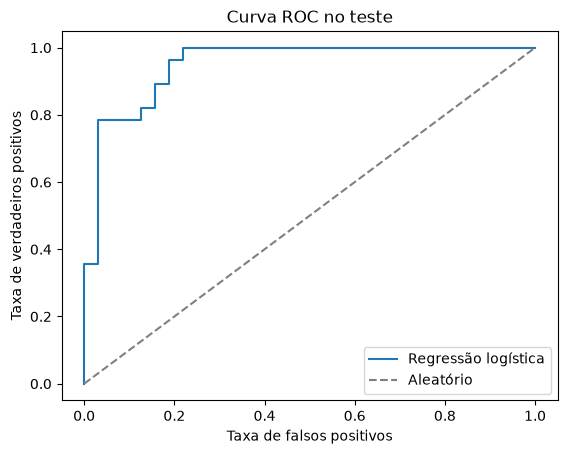

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label='Regressão logística')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Aleatório')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC no teste')
plt.legend()
plt.show()

### Desempenho no teste

| Métrica | Valor | Interpretação |
|---|---:|---|
| Acurácia | **0,8333** | 50 dos 60 registros foram classificados corretamente. |
| Precisão da classe 1 | **0,8462** | 22 dos 26 previstos como positivos eram positivos. |
| Recall da classe 1 | **0,7857** | 22 dos 28 positivos foram detectados. |
| F1 da classe 1 | **0,8148** | Média harmônica entre precisão e recall. |
| AUC ROC | **0,9498** | Boa capacidade de ordenar positivos acima de negativos neste teste. |

### Erros e consequências clínicas

| Erro | Casos no teste | Possível consequência em uma triagem |
|---|---:|---|
| **Falso negativo** | **6** pacientes com doença classificados como negativos | Deixar de encaminhar um paciente que precisa de avaliação, atrasando o diagnóstico e o tratamento. |
| **Falso positivo** | **4** pacientes sem doença classificados como positivos | Gerar preocupação, custos e exames adicionais desnecessários. |

### Qual erro é mais crítico?

Em uma aplicação de triagem de doença cardíaca, a prioridade tende a ser reduzir os falsos negativos, pois deixar de identificar a doença pode adiar cuidados necessários. Neste teste, o modelo deixou de detectar 6 dos 28 pacientes com doença (21,4%), apesar da acurácia de 83,3%.

Essa prioridade depende do contexto: falsos positivos também têm custos e podem levar a procedimentos com riscos. Por isso, a escolha deve considerar a gravidade da doença e o que acontece após cada previsão.
